# Chapitre 8 - Exercices 8.5 à 8.7

* **8.5** - Généraliser les fonctions de perte de la figure 10.4 à plus de deux classes.
* **8.6** - Données de densité osseuse : spline de lissage, bandes fréquentistes,
  bayésiennes et bootstrap.
* **8.7** - L'algorithme EM vu comme un algorithme MM (minoration-maximisation).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## Exercice 8.5 : Fonctions de perte pour plus de deux classes

**Énoncé.** Proposer des généralisations à plus de deux classes de chacune des fonctions
de perte de la figure 10.4 du livre, et concevoir un graphique adapté pour les comparer.

### Rappel : la figure 10.4 (cas à deux classes)

Avec $y \in \{-1, +1\}$, une fonction de score $f(x) \in \mathbb R$ et la règle
$\hat G(x) = \mathrm{signe}(f(x))$, toutes les pertes s'écrivent en fonction de la
**marge** $yf$ :

| perte | formule | rôle |
|---|---|---|
| erreur de classement | $\mathbb 1\{yf < 0\}$ | critère visé |
| exponentielle | $e^{-yf}$ | AdaBoost (chap. 10) |
| déviance binomiale | $\log(1 + e^{-2yf})$ | régression logistique |
| erreur quadratique | $(y - f)^2 = (1 - yf)^2$ | régression sur l'indicatrice |
| « support vector » | $(1 - yf)_+$ | SVM (chap. 12) |

Dans la figure 10.4, chaque perte est normalisée pour valoir 1 en $yf = 0$ (la déviance est
divisée par $\log 2$).

### Codage à $K$ classes

On utilise un **vecteur de scores** $f = (f_1, \dots, f_K)$ soumis à la contrainte
$\sum_k f_k = 0$ (sans elle, ajouter une constante à tous les $f_k$ ne changerait pas le
classement) et la règle $\hat G = \arg\max_k f_k$. La classe observée $k$ est codée par le
vecteur symétrique (codage de Zhu et al., repris pour AdaBoost multiclasse)

$$y_j = 1 \text{ si } j = k, \qquad y_j = -\tfrac{1}{K-1} \text{ sinon},
\qquad\text{de sorte que } \textstyle\sum_j y_j = 0.$$

Pour $K = 2$, $y = (\pm 1, \mp 1)$ et $f = (f_1, -f_1)$ : on retrouve le cadre à deux
classes avec $f = f_1$.

### Les généralisations proposées

| perte | généralisation à $K$ classes (classe observée $k$) | valeur en $f = 0$ |
|---|---|---|
| erreur de classement | $\mathbb 1\{\arg\max_j f_j \ne k\}$ | - |
| exponentielle | $\exp\big(-\tfrac1K\,y^Tf\big)$ | 1 |
| déviance multinomiale | $-\log p_k(f)$, $p_k = e^{f_k}/\sum_j e^{f_j}$ (éq. (4.17), (10.22)) | $\log K$ |
| erreur quadratique | $\sum_j (y_j - f_j)^2$ | $K/(K-1)$ |
| « support vector » (Lee, Lin, Wahba) | $\sum_{j\ne k}\big(f_j + \tfrac{1}{K-1}\big)_+$ | 1 |
| « support vector » (Crammer, Singer) | $\big(1 - [f_k - \max_{j\ne k}f_j]\big)_+$ | 1 |

Pour comparer, on normalise comme dans la figure 10.4 pour que chaque perte vaille 1 en
$f = 0$ (déviance divisée par $\log K$, erreur quadratique multipliée par $(K-1)/K$).

### Vérification : retour au cas $K = 2$

Avec $K = 2$, $y = (1, -1)$ et $f = (f_1, -f_1)$ :

* exponentielle : $y^Tf/2 = (f_1 + f_1)/2 = f_1$, donc $e^{-f_1}$ ✓ ;
* déviance : $p_1 = e^{f_1}/(e^{f_1} + e^{-f_1}) = 1/(1 + e^{-2f_1})$, donc
  $-\log p_1 = \log(1 + e^{-2f_1})$ ✓ ;
* quadratique : $(1 - f_1)^2 + (-1 + f_1)^2 = 2(1 - f_1)^2$, normalisée : $(1 - f_1)^2$ ✓ ;
* Lee-Lin-Wahba : $(f_2 + 1)_+ = (1 - f_1)_+$ ✓ ;
* Crammer-Singer : $(1 - 2f_1)_+$ : c'est la perte SVM à un changement d'échelle de $f$ près.

In [2]:
def coding(k, K):
    y = np.full(K, -1.0 / (K - 1)); y[k] = 1.0
    return y

def losses(f, k):
    """Pertes multiclasses normalisées (valent 1 en f = 0). f : (n, K), classe observée k."""
    K = f.shape[1]
    y = coding(k, K)
    others = np.delete(np.arange(K), k)
    logp = f[:, k] - np.log(np.exp(f).sum(1))
    margin = f[:, k] - f[:, others].max(1)
    return {
        "erreur de classement": (f.argmax(1) != k).astype(float),
        "exponentielle": np.exp(-f @ y / K),
        "déviance multinomiale": -logp / np.log(K),
        "erreur quadratique": ((y - f) ** 2).sum(1) * (K - 1) / K,
        "SVM (Lee-Lin-Wahba)": np.clip(f[:, others] + 1 / (K - 1), 0, None).sum(1),
        "SVM (Crammer-Singer)": np.clip(1 - margin, 0, None),
    }

t = np.linspace(-2, 2, 9)
f2 = np.column_stack([t, -t])
L2 = losses(f2, 0)
print("K = 2, vérification des formules à deux classes :")
print("  exponentielle :", np.allclose(L2["exponentielle"], np.exp(-t)))
print("  déviance      :", np.allclose(L2["déviance multinomiale"], np.log1p(np.exp(-2 * t)) / np.log(2)))
print("  quadratique   :", np.allclose(L2["erreur quadratique"], (1 - t) ** 2))
print("  SVM (LLW)     :", np.allclose(L2["SVM (Lee-Lin-Wahba)"], np.clip(1 - t, 0, None)))

K = 2, vérification des formules à deux classes :
  exponentielle : True
  déviance      : True
  quadratique   : True
  SVM (LLW)     : True


### Premier graphique : une coupe à une dimension

Le long de la direction du codage, $f = t\,y$ (on augmente le score de la bonne classe et
l'on diminue uniformément les autres), $t$ joue le rôle de la marge $yf$ : on obtient
l'analogue direct de la figure 10.4. Un calcul simple donne $e^{-t/(K-1)}$ pour
l'exponentielle, $(1 - t)^2$ pour la quadratique et $(1 - t)_+$ pour Lee-Lin-Wahba.

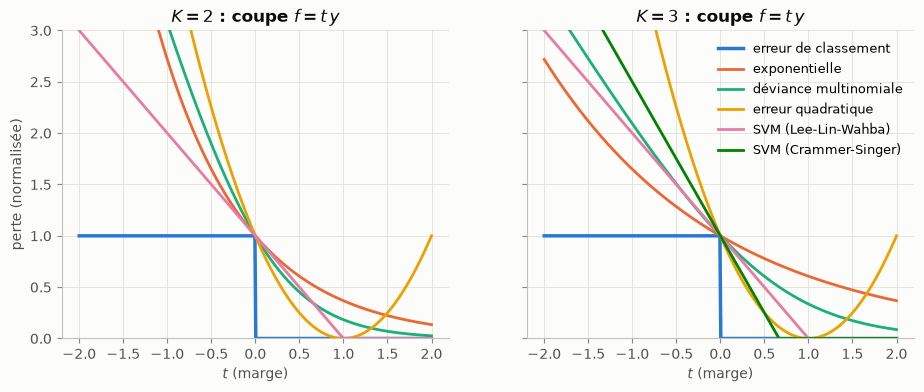

In [3]:
tt = np.linspace(-2, 2, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, K in zip(ax, [2, 3]):
    Lk = losses(tt[:, None] * coding(0, K)[None, :], 0)
    for c, (name, v) in zip(COLORS, Lk.items()):
        if K == 2 and name == "SVM (Crammer-Singer)":
            continue
        a.plot(tt, v, color=c, label=name, lw=2 if name != "erreur de classement" else 2.5)
    a.set(title="$K = %d$ : coupe $f = t\\,y$" % K, xlabel="$t$ (marge)", ylim=(0, 3))
ax[0].set_ylabel("perte (normalisée)")
ax[1].legend(loc="upper right")
plt.show()

Cette coupe ne montre qu'une direction : avec $K \ge 3$, une perte dépend de **tout** le
vecteur $f$, en particulier de la façon dont se répartissent les scores des mauvaises
classes.

### Second graphique : le plan $\sum_k f_k = 0$ pour $K = 3$

Pour $K = 3$, les scores admissibles forment un plan, que l'on paramètre par une base
orthonormée $(e_1, e_2)$ : $f = u\,e_1 + v\,e_2$. On choisit $e_1$ colinéaire au codage
de la classe 1 (vraie classe). Les traits gris délimitent les régions où chaque classe
est prédite ; la région de bonne classification est à droite.

In [4]:
K = 3
e1 = coding(0, K) / np.linalg.norm(coding(0, K))
e2 = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)
uu, vv = np.meshgrid(np.linspace(-2.5, 2.5, 241), np.linspace(-2.5, 2.5, 241))
Fp = uu.ravel()[:, None] * e1 + vv.ravel()[:, None] * e2
L3 = losses(Fp, 0)

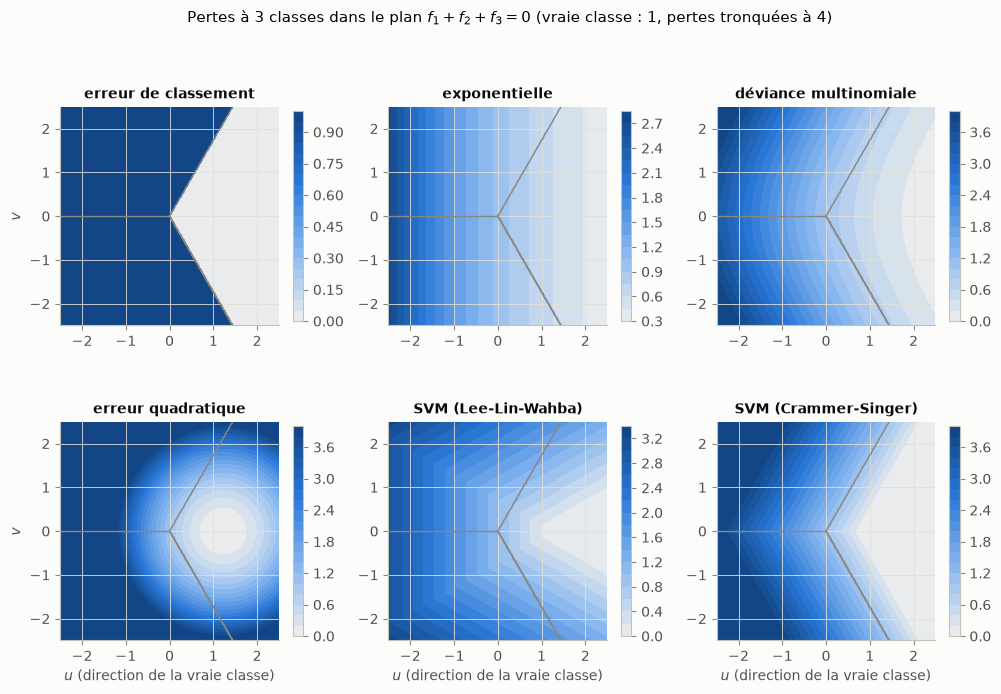

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for a, (name, v) in zip(axes.ravel(), L3.items()):
    im = a.contourf(uu, vv, np.minimum(v, 4).reshape(uu.shape), levels=20, cmap=SEQ)
    a.contour(uu, vv, Fp.argmax(1).reshape(uu.shape), levels=[0.5, 1.5], colors=GRAY,
              linewidths=1)
    a.set_title(name, fontsize=10)
    a.set_aspect("equal")
    fig.colorbar(im, ax=a, shrink=0.8)
for a in axes[1]:
    a.set_xlabel("$u$ (direction de la vraie classe)")
for a in axes[:, 0]:
    a.set_ylabel("$v$")
fig.suptitle("Pertes à 3 classes dans le plan $f_1+f_2+f_3=0$ (vraie classe : 1, pertes tronquées à 4)",
             fontsize=11)
plt.show()

On lit sur ces cartes :

* l'exponentielle et la déviance décroissent dans toute la région de bonne classification
  (elles continuent à « pousser » la marge) ; l'exponentielle croît exponentiellement
  dans la mauvaise région, la déviance seulement linéairement (plus robuste) ;
* la perte quadratique pénalise aussi les scores **trop** grands (bol centré sur le
  codage) ;
* les deux pertes SVM sont nulles au-delà d'une marge, mais avec des géométries
  différentes : Lee-Lin-Wahba pénalise chaque mauvaise classe séparément,
  Crammer-Singer seulement la plus menaçante.

### Un critère de comparaison : la cohérence de Fisher

Une perte est **Fisher-cohérente** si le minimiseur de la perte espérée
$E[L(Y, f)\mid x] = \sum_k p_k L(k, f)$ (avec $p_k = \Pr(Y = k\mid x)$) prédit la classe de
Bayes $\arg\max_k p_k$. Calculons ces minimiseurs numériquement pour deux vecteurs $p$
(dans le plan, à l'aide de Nelder-Mead).

In [6]:
def expected_loss(uv, p, name):
    f = (uv[0] * e1 + uv[1] * e2)[None, :]
    return sum(p[k] * losses(f, k)[name][0] for k in range(K))

for p in [np.array([0.6, 0.25, 0.15]), np.array([0.4, 0.35, 0.25])]:
    print("p =", p)
    for name in list(L3)[1:]:
        best = min((optimize.minimize(expected_loss, x0, args=(p, name), method="Nelder-Mead",
                                      options={"xatol": 1e-7, "fatol": 1e-10, "maxiter": 4000})
                    for x0 in rng.randn(6, 2)), key=lambda r: r.fun)
        f_opt = best.x[0] * e1 + best.x[1] * e2
        print("   %-24s f* = %s" % (name, np.round(f_opt, 3)))

p = [0.6  0.25 0.15]
   exponentielle            f* = [ 1.508 -0.243 -1.265]
   déviance multinomiale    f* = [ 0.754 -0.122 -0.632]
   erreur quadratique       f* = [ 0.4   -0.125 -0.275]
   SVM (Lee-Lin-Wahba)      f* = [ 1.  -0.5 -0.5]


   SVM (Crammer-Singer)     f* = [ 0.667 -0.333 -0.333]
p = [0.4  0.35 0.25]
   exponentielle            f* = [ 0.402  0.135 -0.538]
   déviance multinomiale    f* = [ 0.201  0.068 -0.269]
   erreur quadratique       f* = [ 0.1    0.025 -0.125]


   SVM (Lee-Lin-Wahba)      f* = [ 1.  -0.5 -0.5]
   SVM (Crammer-Singer)     f* = [ 0.  0. -0.]


* Exponentielle et déviance donnent des scores **ordonnés comme $p$** (pour la déviance,
  $f^*_k = \log p_k - \frac1K\sum_j\log p_j$, et l'on retrouve les probabilités par
  *softmax*) ; la perte quadratique aussi ($f^* = E[y\mid x]$, affine en $p$).
* Lee-Lin-Wahba donne $f^* = (1, -\frac12, -\frac12)$ : elle n'estime pas les
  probabilités, mais désigne la bonne classe.
* Crammer-Singer, lorsque aucune classe ne dépasse $1/2$ (second $p$), donne un
  minimiseur dégénéré ($f^* \approx 0$, ou une classe arbitraire) : elle **n'est pas**
  Fisher-cohérente en général.

> **À retenir.** Les pertes à deux classes s'étendent naturellement à $K$ classes avec
> un codage symétrique et la contrainte $\sum_k f_k = 0$. Une coupe 1D ne suffit plus
> pour les comparer ; des cartes dans le plan des scores et l'étude de leurs minimiseurs
> (cohérence de Fisher) révèlent des différences invisibles à deux classes.

## Exercice 8.6 : Densité minérale osseuse : trois types de bandes

**Énoncé.** On considère les données de densité minérale osseuse de la figure 5.6.

(a) Ajuster une spline de lissage cubique à la variation relative de la densité
minérale osseuse vertébrale (`spnbmd`) en fonction de l'âge, en choisissant la quantité
de lissage par validation croisée, puis construire des bandes de confiance ponctuelles à
90 % pour la fonction sous-jacente.

(b) Calculer la moyenne et la covariance a posteriori de la vraie fonction par (8.28) et
comparer les bandes a posteriori à celles de (a).

(c) Calculer 100 réplications bootstrap des courbes ajustées, comme dans la figure 8.2
(en bas à gauche), et comparer avec (a) et (b).

### Rappels : la spline de lissage (section 5.4)

La spline de lissage minimise
$\sum_i (y_i - f(x_i))^2 + \lambda\int f''(t)^2\,dt$. Son minimiseur est une spline
cubique (naturelle) à nœuds aux $x_i$ distincts. En l'écrivant dans une base de B-splines
cubiques à nœuds aux âges distincts, $f(x) = h(x)^T\beta$, le critère devient

$$\|y - H\beta\|^2 + \lambda\,\beta^T\Omega\beta, \qquad \Omega_{jk} = \int h_j''h_k'',$$

d'où $\hat\beta = (H^TH + \lambda\Omega)^{-1}H^Ty$ et $\hat f = S_\lambda y$ avec
$S_\lambda = H(H^TH + \lambda\Omega)^{-1}H^T$ (matrice de lissage). Le nombre de degrés
de liberté effectifs est $\mathrm{df}_\lambda = \mathrm{tr}(S_\lambda)$, et l'erreur de
validation croisée « leave-one-out » se calcule sans réajustement :
$\mathrm{CV}(\lambda) = \frac1N\sum_i\big[(y_i - \hat f(x_i))/(1 - S_{ii})\big]^2$.

In [7]:
bone = datasets.load_bone()
groups = {g: (d["age"].values, d["spnbmd"].values) for g, d in bone.groupby("gender")}
for g, (a, s) in groups.items():
    print("%-6s : %d mesures, %d âges distincts, âge de %.1f à %.1f ans"
          % (g, len(a), len(np.unique(a)), a.min(), a.max()))

female : 259 mesures, 168 âges distincts, âge de 9.4 à 25.6 ans
male   : 226 mesures, 152 âges distincts, âge de 9.6 à 25.2 ans


In [8]:
def ss_setup(x):
    """Base de B-splines à nœuds aux valeurs distinctes de x, et matrice de pénalité."""
    u = np.unique(x)
    knots = inf.bspline_knots(u[1:-1], (u[0], u[-1]))
    return knots, inf.bspline_basis(x, knots), inf.bspline_penalty(knots)

lams = np.logspace(-3, 3, 50)
fits = {}
for g, (x, y) in groups.items():
    knots, H, Om = ss_setup(x)
    Ss = [inf.smoother_matrix(H, Om, l) for l in lams]
    cv = [inf.loocv_linear_smoother(S, y) for S in Ss]
    dfs = [np.trace(S) for S in Ss]
    fits[g] = dict(x=x, y=y, knots=knots, H=H, Om=Om, cv=np.array(cv), dfs=np.array(dfs),
                   lam=lams[int(np.argmin(cv))])
    print("%-6s : lambda choisi = %.2e, df = %.1f" % (g, fits[g]["lam"], dfs[int(np.argmin(cv))]))

female : lambda choisi = 6.25e+00, df = 8.1
male   : lambda choisi = 1.93e+01, df = 6.1


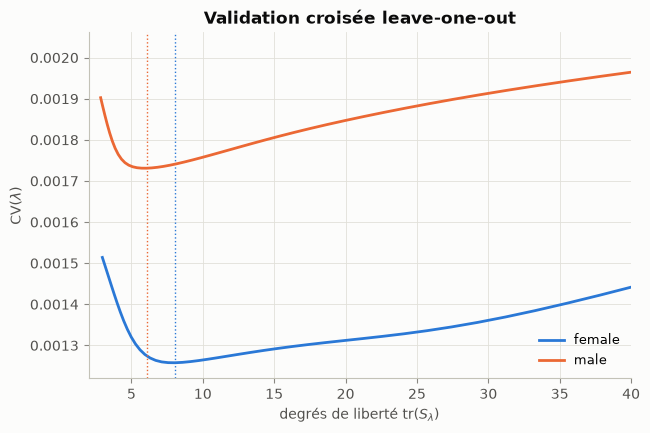

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, g in zip([BLUE, ORANGE], fits):
    ax.plot(fits[g]["dfs"], fits[g]["cv"], color=c, label=g)
    ax.axvline(fits[g]["dfs"][np.argmin(fits[g]["cv"])], color=c, ls=":", lw=1)
ax.set(title="Validation croisée leave-one-out", xlabel=r"degrés de liberté $\mathrm{tr}(S_\lambda)$",
       ylabel=r"CV$(\lambda)$", xlim=(2, 40))
ax.legend()
plt.show()

### (a) Bandes fréquentistes

À $\lambda$ fixé, $\hat f(x_0) = \ell(x_0)^Ty$ avec
$\ell(x_0)^T = h(x_0)^T(H^TH + \lambda\Omega)^{-1}H^T$. Si
$\mathrm{Var}(y) = \sigma^2 I$, alors

$$\mathrm{Var}[\hat f(x_0)] = \sigma^2\|\ell(x_0)\|^2 = \sigma^2\,h(x_0)^TA^{-1}H^THA^{-1}h(x_0),
\qquad A = H^TH + \lambda\Omega.$$

On estime $\sigma^2$ par $\hat\sigma^2 = \mathrm{RSS}/(N - \mathrm{tr}\,S_\lambda)$, et la
bande ponctuelle à 90 % est $\hat f(x_0) \pm 1{,}645\,\widehat{\mathrm{se}}$ ($1{,}645$ est
le quantile à 95 % de $N(0,1)$).

> **Remarque.** Ces bandes encadrent $E[\hat f(x_0)]$, pas $f(x_0)$ : elles ignorent le
> **biais** du lissage, qui n'est pas nul quand $\lambda > 0$.

In [10]:
for g, F in fits.items():
    x, y, H, Om, lam = F["x"], F["y"], F["H"], F["Om"], F["lam"]
    A_inv = np.linalg.inv(H.T @ H + lam * Om)
    beta = A_inv @ H.T @ y
    S = H @ A_inv @ H.T
    F["sigma2"] = np.sum((y - H @ beta) ** 2) / (len(y) - np.trace(S))
    F["grid"] = np.linspace(x.min(), x.max(), 200)
    Hg = inf.bspline_basis(F["grid"], F["knots"])
    F["Hg"], F["beta"], F["A_inv"] = Hg, beta, A_inv
    F["fhat"] = Hg @ beta
    F["se_freq"] = np.sqrt(F["sigma2"] * np.sum((Hg @ A_inv @ H.T) ** 2, axis=1))
    print("%-6s : sigma2_hat = %.5f" % (g, F["sigma2"]))

female : sigma2_hat = 0.00123
male   : sigma2_hat = 0.00171


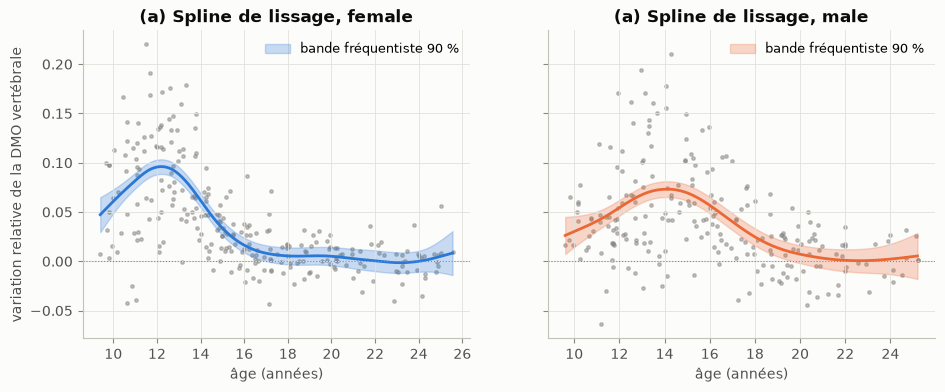

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (g, F), c in zip(ax, fits.items(), [BLUE, ORANGE]):
    a.scatter(F["x"], F["y"], s=6, color=GRAY, alpha=0.5)
    a.plot(F["grid"], F["fhat"], color=c)
    a.fill_between(F["grid"], F["fhat"] - 1.645 * F["se_freq"], F["fhat"] + 1.645 * F["se_freq"],
                   color=c, alpha=0.25, label="bande fréquentiste 90 %")
    a.axhline(0, color=GRAY, lw=0.8, ls=":")
    a.set(title="(a) Spline de lissage, %s" % g, xlabel="âge (années)")
    a.legend(loc="upper right")
ax[0].set_ylabel("variation relative de la DMO vertébrale")
plt.show()

### (b) Bandes bayésiennes

Le lien avec (8.27)-(8.28) : prenons l'a priori $\beta \sim N(0, \tau\Sigma)$ avec
$\Sigma^{-1} = \Omega$ et $\sigma^2/\tau = \lambda$. Alors
$H^TH + \frac{\sigma^2}{\tau}\Sigma^{-1} = H^TH + \lambda\Omega = A$ et (8.28) donne

$$E(f(x)\mid y) = h(x)^TA^{-1}H^Ty = \hat f(x), \qquad
\mathrm{cov}[f(x), f(x')\mid y] = \sigma^2\,h(x)^TA^{-1}h(x').$$

La moyenne a posteriori **est** la spline de lissage. Comme $\Omega$ n'est pas inversible
(les fonctions affines ont une dérivée seconde nulle), cet a priori est **impropre** :
il est plat sur la partie affine de $f$ (limite de $\Sigma^{-1} = \Omega + \varepsilon I$
quand $\varepsilon \to 0$). C'est l'interprétation bayésienne des splines de lissage
(Wahba).

**Comparaison des variances.** On a $\mathrm{Var}_{\text{freq}} = \sigma^2 h^TA^{-1}
(H^TH)A^{-1}h$ et $\mathrm{Var}_{\text{post}} = \sigma^2 h^TA^{-1}(H^TH + \lambda\Omega)
A^{-1}h$. Leur différence vaut $\sigma^2\lambda\,(A^{-1}h)^T\Omega(A^{-1}h) \ge 0$ car
$\Omega$ est semi-définie positive : **les bandes a posteriori sont plus larges**. Le
supplément tient compte, en moyenne, du biais ignoré en (a) ; c'est pourquoi les bandes
bayésiennes ont en pratique une couverture moyenne proche du niveau annoncé.

In [12]:
for F in fits.values():
    F["se_post"] = np.sqrt(F["sigma2"] * np.einsum("ij,jk,ik->i", F["Hg"], F["A_inv"], F["Hg"]))
    print("rapport moyen se_post / se_freq = %.3f" % np.mean(F["se_post"] / F["se_freq"]))

rapport moyen se_post / se_freq = 1.139
rapport moyen se_post / se_freq = 1.132


### (c) Bootstrap

On tire 100 échantillons bootstrap de couples (âge, `spnbmd`), on réajuste la spline avec
la même base et le **même** $\lambda$, et l'on forme une bande à 90 % par les percentiles
5 % et 95 % en chaque âge.

In [13]:
B = 100
for F in fits.values():
    x, y, lam = F["x"], F["y"], F["lam"]
    curves = []
    for idx in inf.bootstrap_indices(len(y), B, rng):
        Hb = inf.bspline_basis(x[idx], F["knots"])
        bb = np.linalg.solve(Hb.T @ Hb + lam * F["Om"], Hb.T @ y[idx])
        curves.append(F["Hg"] @ bb)
    F["boot"] = np.array(curves)
    F["boot_lo"], F["boot_hi"] = np.percentile(F["boot"], [5, 95], axis=0)

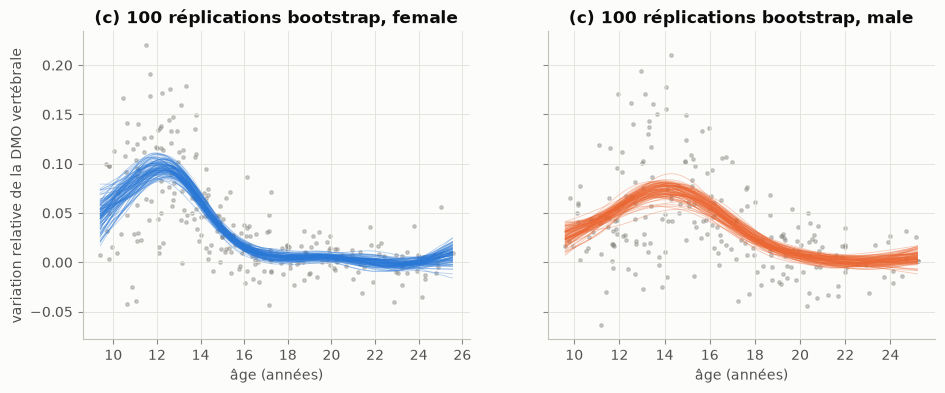

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (g, F), c in zip(ax, fits.items(), [BLUE, ORANGE]):
    a.scatter(F["x"], F["y"], s=6, color=GRAY, alpha=0.4)
    for b in range(B):
        a.plot(F["grid"], F["boot"][b], color=c, lw=0.6, alpha=0.35)
    a.set(title="(c) 100 réplications bootstrap, %s" % g, xlabel="âge (années)")
ax[0].set_ylabel("variation relative de la DMO vertébrale")
plt.show()

### Comparaison des trois bandes

On superpose les trois bandes (femmes), puis on compare leurs **demi-largeurs** en
fonction de l'âge pour les deux sexes.

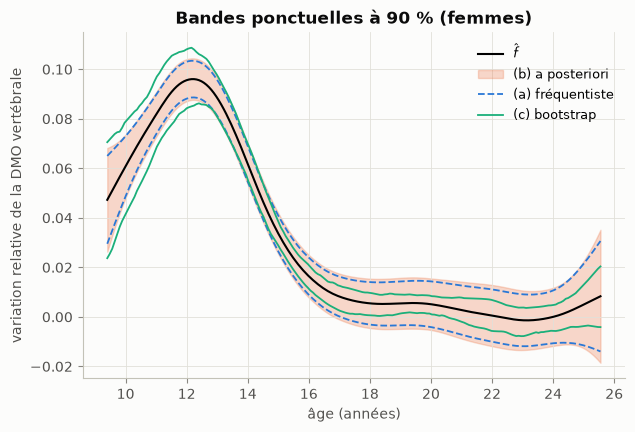

In [15]:
F = fits["female"]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(F["grid"], F["fhat"], color="k", lw=1.5, label=r"$\hat f$")
ax.fill_between(F["grid"], F["fhat"] - 1.645 * F["se_post"], F["fhat"] + 1.645 * F["se_post"],
                color=ORANGE, alpha=0.25, label="(b) a posteriori")
ax.plot(F["grid"], F["fhat"] - 1.645 * F["se_freq"], color=BLUE, ls="--", lw=1.3,
        label="(a) fréquentiste")
ax.plot(F["grid"], F["fhat"] + 1.645 * F["se_freq"], color=BLUE, ls="--", lw=1.3)
ax.plot(F["grid"], F["boot_lo"], color=COLORS[2], lw=1.3, label="(c) bootstrap")
ax.plot(F["grid"], F["boot_hi"], color=COLORS[2], lw=1.3)
ax.set(title="Bandes ponctuelles à 90 % (femmes)", xlabel="âge (années)",
       ylabel="variation relative de la DMO vertébrale")
ax.legend()
plt.show()

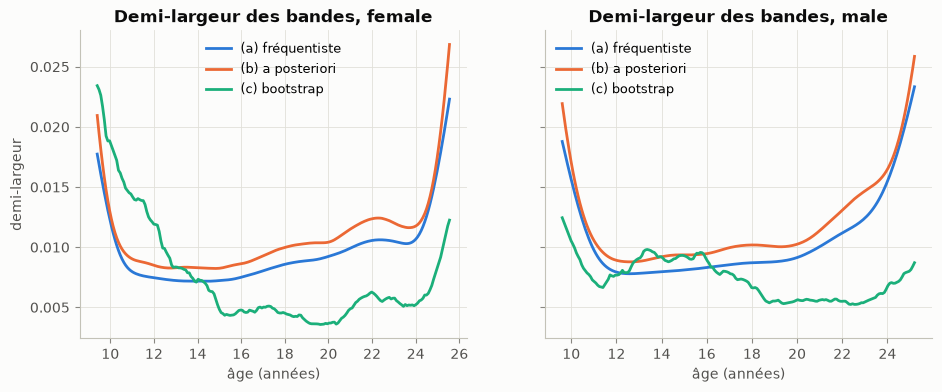

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (g, F) in zip(ax, fits.items()):
    a.plot(F["grid"], 1.645 * F["se_freq"], color=BLUE, label="(a) fréquentiste")
    a.plot(F["grid"], 1.645 * F["se_post"], color=ORANGE, label="(b) a posteriori")
    a.plot(F["grid"], (F["boot_hi"] - F["boot_lo"]) / 2, color=COLORS[2], label="(c) bootstrap")
    a.set(title="Demi-largeur des bandes, %s" % g, xlabel="âge (années)")
    a.legend()
ax[0].set_ylabel("demi-largeur")
plt.show()

**Bilan de la comparaison.**

* (a) et (c) sont du même ordre : à $\lambda$ fixé, le bootstrap non paramétrique estime
  la même variance d'échantillonnage que la formule, avec plus de bruit (100 réplications
  seulement) et en restant valable si la variance du bruit n'est pas constante (le bruit
  est ici nettement plus fort à l'adolescence).
* (b) est un peu plus large partout ($\mathrm{Var}_{\text{post}} \ge \mathrm{Var}_{\text{freq}}$)
  car elle intègre l'incertitude sur la fonction elle-même (le biais).
* Comme dans la figure 8.2, toutes les bandes s'élargissent aux extrémités, où les
  données sont rares.

> **Remarque.** Plusieurs mesures proviennent du même adolescent (variable `idnum`) : les
> observations ne sont pas indépendantes. Un bootstrap plus fidèle rééchantillonnerait les
> **individus** plutôt que les mesures ; nous suivons ici l'énoncé.

> **À retenir.** Pour une spline de lissage, la moyenne a posteriori sous l'a priori
> gaussien $\Sigma^{-1} = \Omega$, $\sigma^2/\tau = \lambda$ est la spline elle-même ; la
> covariance a posteriori $\sigma^2 HA^{-1}H^T = \sigma^2 S_\lambda$ domine la covariance
> fréquentiste $\sigma^2 S_\lambda S_\lambda^T$, et le bootstrap reproduit cette dernière.

## Exercice 8.7 : EM comme algorithme de minoration-maximisation (MM)

**Énoncé.** Une fonction $g(x, y)$ **minore** $f(x)$ si

$$g(x, y) \le f(x), \qquad g(x, x) = f(x) \qquad \text{pour tous } x, y.
\qquad \text{(éq. (8.62))}$$

On en déduit facilement que $f$ ne décroît pas sous l'itération
$x_{s+1} = \arg\max_x g(x, x_s)$ (éq. (8.63)) : c'est le principe des algorithmes **MM**
(« minoration-maximisation », ou « majoration-minimisation » pour minimiser). Montrer que
l'algorithme EM (section 8.5.2) est un algorithme MM, en utilisant
$Q(\theta', \theta) + \log\Pr(Z\mid\theta) - Q(\theta, \theta)$ pour minorer la
log-vraisemblance observée $\ell(\theta'; Z)$ (seul le premier terme dépend de
l'argument $\theta'$).

### Rappels

* $\ell(\theta'; Z) = \log\Pr(Z\mid\theta')$.
* Décomposition (8.46), valable pour tous $\theta, \theta'$ :
  $\ell(\theta'; Z) = Q(\theta', \theta) - R(\theta', \theta)$ avec
  $Q(\theta', \theta) = E[\ell_0(\theta'; T)\mid Z, \theta]$ et
  $R(\theta', \theta) = E[\log\Pr(Z^m\mid Z, \theta')\mid Z, \theta]$.
* Exercice 8.1 : $R(\theta', \theta) \le R(\theta, \theta)$.

### Solution

**La monotonie des algorithmes MM.** Si $g$ minore $f$ et $x_{s+1}$ maximise
$g(\cdot, x_s)$ :

$$f(x_{s+1}) \ \ge\ g(x_{s+1}, x_s) \ \ge\ g(x_s, x_s) \ =\ f(x_s),$$

la première inégalité par minoration, la deuxième par définition du maximum, l'égalité
par la condition de contact.

**La fonction minorante d'EM.** Posons
$g(\theta', \theta) = Q(\theta', \theta) + \ell(\theta; Z) - Q(\theta, \theta)$.

1. *Contact* : $g(\theta, \theta) = Q(\theta, \theta) + \ell(\theta; Z) - Q(\theta, \theta)
   = \ell(\theta; Z)$.
2. *Minoration* : d'après (8.46) appliquée en $\theta'$ puis en $\theta$,
   $\ell(\theta'; Z) = Q(\theta', \theta) - R(\theta', \theta)$ et
   $\ell(\theta; Z) = Q(\theta, \theta) - R(\theta, \theta)$. Donc
   $$\ell(\theta'; Z) - g(\theta', \theta) = -R(\theta', \theta) - \ell(\theta; Z) +
   Q(\theta, \theta) = R(\theta, \theta) - R(\theta', \theta) \ \ge\ 0$$
   par l'exercice 8.1. Ainsi $g(\theta', \theta) \le \ell(\theta'; Z)$ pour tous
   $\theta, \theta'$.
3. *Maximisation* : $\ell(\theta; Z) - Q(\theta, \theta)$ ne dépend pas de $\theta'$, donc
   $\arg\max_{\theta'} g(\theta', \theta_s) = \arg\max_{\theta'} Q(\theta', \theta_s)$ :
   c'est exactement l'étape M.

EM est donc l'algorithme MM associé à la minorante $g$, et la monotonie
$\ell(\theta_{s+1}) \ge \ell(\theta_s)$ découle de l'argument général ci-dessus.

> **Remarque.** L'écart $\ell(\theta') - g(\theta', \theta) = \mathrm{KL}\big(
> \Pr(Z^m\mid Z, \theta)\,\|\,\Pr(Z^m\mid Z, \theta')\big)$ : la minorante est d'autant
> plus serrée que les lois conditionnelles des données latentes sont proches.

### Illustration sur le mélange de gaussiennes

On trace, pour quelques itérations EM $\theta_s$ sur les données du tableau 8.1, la
log-vraisemblance $\ell(\theta')$ et la minorante $g(\theta', \theta_s)$ le long d'une
coupe : $\theta'$ égal à $\theta_{s+1}$ sauf $\mu_2'$, que l'on fait varier.

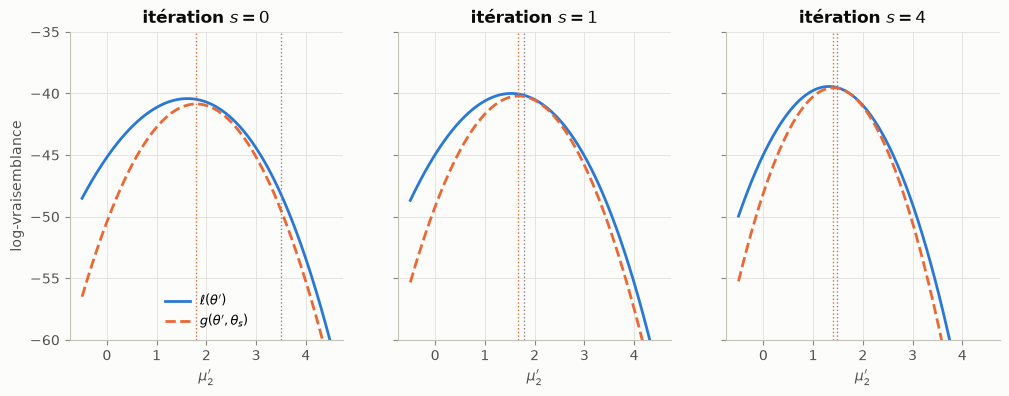

In [17]:
y = inf.MIXTURE_DATA
traj = inf.em_mixture(y, (5.0, 1.0, 3.5, 1.0, 0.5), n_iter=30)

def g_minor(theta_new, theta_old):
    return (inf.mixture_Q(y, theta_new, theta_old) + inf.mixture_loglik(y, theta_old)
            - inf.mixture_Q(y, theta_old, theta_old))

m2 = np.linspace(-0.5, 4.5, 300)
fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for a, s in zip(ax, [0, 1, 4]):
    th_s, th_next = traj["thetas"][s], traj["thetas"][s + 1]
    cut = lambda m: (th_next[0], th_next[1], m, th_next[3], th_next[4])
    a.plot(m2, [inf.mixture_loglik(y, cut(m)) for m in m2], color=BLUE,
           label=r"$\ell(\theta')$")
    a.plot(m2, [g_minor(cut(m), th_s) for m in m2], color=ORANGE, ls="--",
           label=r"$g(\theta', \theta_s)$")
    a.axvline(th_s[2], color=GRAY, ls=":", lw=1)
    a.axvline(th_next[2], color=ORANGE, ls=":", lw=1)
    a.set(title="itération $s = %d$" % s, xlabel=r"$\mu_2'$", ylim=(-60, -35))
ax[0].set_ylabel("log-vraisemblance")
ax[0].legend(loc="lower center")
plt.show()

La minorante (orange) reste sous la log-vraisemblance (bleu) ; le pointillé orange marque
la nouvelle valeur $\mu_2^{(s+1)}$, maximiseur de la minorante. (Le long de cette coupe, le
point de contact n'est pas visible car $\theta_s$ diffère de $\theta_{s+1}$ aussi par
les autres paramètres.)

Vérifions enfin les trois propriétés sur des paires $(\theta', \theta)$ tirées au hasard
et la monotonie le long de la trajectoire.

In [18]:
def rand_theta():
    return (rng.uniform(0, 6), rng.uniform(0.3, 3), rng.uniform(0, 6), rng.uniform(0.3, 3),
            rng.uniform(0.1, 0.9))

gaps = []
for _ in range(2000):
    th, thp = rand_theta(), rand_theta()
    gaps.append(inf.mixture_loglik(y, thp) - g_minor(thp, th))
contact = max(abs(g_minor(th, th) - inf.mixture_loglik(y, th))
              for th in [rand_theta() for _ in range(100)])
print("min de l(theta') - g(theta', theta) sur 2000 paires : %.2e (>= 0)" % min(gaps))
print("max |g(theta, theta) - l(theta)|                    : %.2e" % contact)
print("log-vraisemblance non décroissante le long d'EM     :",
      bool(np.all(np.diff(traj["loglik"]) >= -1e-12)))

min de l(theta') - g(theta', theta) sur 2000 paires : 3.53e-02 (>= 0)
max |g(theta, theta) - l(theta)|                    : 1.42e-14
log-vraisemblance non décroissante le long d'EM     : True


> **À retenir.** $g(\theta', \theta) = Q(\theta', \theta) + \ell(\theta) - Q(\theta, \theta)$
> minore la log-vraisemblance et la touche en $\theta' = \theta$ ; la maximiser revient à
> maximiser $Q$ : EM est un algorithme MM, d'où sa monotonie.